# Flujos de trabajo macroeconómicos insignia de PureMacro v6.0.0: modelado diferenciable unificado, SMC templado, HANK global no lineal, default soberano cuantitativo, proyecciones locales distributivas e IAM espacial climático

**¿Cómo unificamos el modelado macroeconómico diferenciable, el método de Monte Carlo secuencial vectorizado con gradientes de score, HANK global no lineal en espacio de secuencias con riesgo agregado, default soberano cuantitativo con restricciones de colateral, proyecciones locales distributivas funcionales con aditividad exacta y transiciones espaciales climáticas-macroeconómicas en un marco auditado sin servidor en NumPy puro?**

La macroeconomía cuantitativa en la frontera de investigación requiere dominar simultáneamente la heterogeneidad microeconómica de alta dimensión, la fragilidad financiera internacional, las transiciones climáticas espaciales de largo plazo y la inferencia bayesiana y empírica rigurosa. El lanzamiento mayor `puremacro v6.0.0` establece una base matemática unificada para estos dominios bajo un estricto contrato de ejecución sin servidor con solo cuatro paquetes (`numpy`, `scipy`, `pandas`, `matplotlib`). Este cuaderno insignia reúne los seis componentes de la versión en un flujo reproducible de extremo a extremo con una tarjeta de verificación de 14 métricas y visualización de calidad de publicación.

| Alcance y verificación | |
|---|---|
| Flujos cubiertos | 1. Protocolo unificado de modelo diferenciable y limpieza de versión 6.0.0 (`puremacro.core.protocol`: `DifferentiableModel`, `wrap_differentiable_model`, gradientes de score AD); 2. Motor SMC templado vectorizado (`puremacro.inference.smc`: `smc_sample`, templado adaptativo por ESS, mutación MALA, densidad marginal de datos $\log p(Y)$); 3. HANK global no lineal con riesgo agregado (`puremacro.dsge.hank_nonlinear`: `solve_hank_nonlinear_transition`, actualizaciones Broyden de SSJ dependientes del estado, reducción de momentos Winberry–Reiter `solve_hank_aggregate_risk_order2`); 4. Default soberano cuantitativo y parada súbita (`puremacro.sovereign`: default Arellano/Chatterjee–Eyigungor, restricciones de colateral Mendoza, descomposición de estructura temporal de spreads, reestructuración de deuda); 5. Proyecciones locales funcionales y distributivas (`puremacro.lp.distributional`: `estimate_distributional_lp`, `estimate_quantile_lp`, aditividad exacta en subespacio nulo $\sum_b \beta_{b,h} = 0$, puente `bridge_hank_distributional_irf`); 6. IAM espacial climático-macroeconómico integrado (`puremacro.climate.spatial_iam`: `SpatialClimateIAM`, `solve_spatial_climate_iam`, conservación de población, balance de masa de carbono, reducción de fuga de carbono CBAM, impuesto pigouviano de Golosov); 7. Escenario de política integrado general: Transición de descarbonización global que conecta migración climática, incidencia distributiva por deciles de consumo y retroalimentación de riesgo soberano |
| Modelos | Modelo de protocolo DSGE nuevo keynesiano de 3 ecuaciones; objetivo de estimación SMC en espacio de estados gaussiano; HANK de dos activos con agentes heterogéneos, restricciones de endeudamiento y riesgo agregado; modelo de default soberano con deuda de largo plazo de Arellano (2008) y Chatterjee–Eyigungor (2012); parada súbita con restricción de colateral de Mendoza (2010); panel microeconómico sintético con participaciones Dirichlet y cambios de escala-ubicación; economía climática espacial dinámica de 3 regiones (Templada, Subtropical, Tropical) con ciclo de carbono multicaja y CBAM |
| Solucionadores y diagnósticos | `wrap_differentiable_model`, `smc_sample`, `solve_hank_nonlinear_transition`, `solve_hank_aggregate_risk_order2`, `solve_sovereign_default`, `solve_sudden_stop`, `decompose_spread_term_structure`, `evaluate_debt_restructuring`, `estimate_distributional_lp`, `estimate_quantile_lp`, `bridge_hank_distributional_irf`, `solve_spatial_climate_iam` |
| Aceptación | Error de gradiente del protocolo diferenciable $< 10^{-4}$ y cero filtraciones de deprecaciones heredadas; log MDD de SMC dentro de 0.15 y etapa final de templado $\phi = 1.0$; residuo de transición HANK no lineal $< 10^{-8}$ y paridad con SSJ lineal en choques pequeños $< 10^{-4}$; error de escala cuadrática de riesgo agregado $< 10^{-6}$; residuo de Bellman de default soberano $< 10^{-4}$, cotas de precio de bonos $[0, (1+r^*)^{-1}]$ y spreads contracíclicos; aditividad transversal exacta de LP distributiva $< 10^{-12}$ y distancia estructural $L_2 \ge 0$; conservación de población en IAM climático espacial $< 10^{-12}$, balance de masa de carbono $< 10^{-12}$ y reducción de fuga de carbono mediante CBAM |

## El método en fórmulas matemáticas

**1. Protocolo unificado de modelo diferenciable.** Cualquier modelo macroeconómico estructural $m \in \text{DifferentiableModel}$ implementa una interfaz uniforme de cinco métodos: respuestas a impulsos $\mathcal{Y}_h = \mathcal{IR}(x)$, simulación estocástica $Y_t = \mathcal{S}(\epsilon_t)$, gradientes analíticos de verosimilitud $\nabla_\theta \ln p(Y|\theta)$ mediante diferenciación automática hacia adelante con `DualArray`, escenarios contrafactuales $\mathcal{C}(\Delta \theta)$ y exportación de tableros interactivos HTML5 sin servidor. Los símbolos obsoletos de v5 (`puremacro.lp.garch_utils` y `puremacro.sigma.sigma_numpy.SigmaObject`) quedan retirados permanentemente mediante lápidas estrictas.

**2. Monte Carlo secuencial (SMC) templado y vectorizado.** Conecta la distribución previa $p(\theta)$ con la posterior $p(\theta|Y)$ a través de etapas adaptativas de templado $\phi_0 = 0 < \phi_1 < \dots < \phi_N = 1$:
$$\pi_n(\theta) \propto p(\theta) p(Y|\theta)^{\phi_n}, \quad \text{con} \quad \phi_{n+1} = \operatorname{solve}\left( \text{ESS}(\phi) = \alpha N \right).$$
La mutación de partículas utiliza deriva de Langevin (MALA) guiada por gradientes de score analíticos:
$$\theta' = \theta + \frac{\epsilon^2}{2} \nabla \ln \pi_n(\theta) + \epsilon \xi, \quad \xi \sim \mathcal{N}(0, \mathbf{I}),$$
produciendo una estimación insesgada de la densidad marginal de datos:
$$\ln \hat{p}(Y) = \sum_{n=1}^N \ln \left( \frac{1}{M} \sum_{i=1}^M \tilde{w}_n^{(i)} \right).$$

**3. HANK global no lineal con riesgo agregado.** Las transiciones en el espacio de secuencias resuelven restricciones de endeudamiento activas mediante jacobianos dependientes del estado $\mathcal{J}(X_t)$ actualizados mediante correcciones de rango 1 de Good Broyden:
$$\mathcal{J}^{(k+1)} = \mathcal{J}^{(k)} + \frac{(y^{(k)} - \mathcal{J}^{(k)} s^{(k)}) s^{(k)\top}}{\|s^{(k)}\|^2}.$$
El acoplamiento con riesgo agregado combina la reducción de momentos transversales de Reiter (2009) y Winberry (2018) con perturbación de Sylvester de segundo orden (`sylvester_order2_tangent`), generando acumulación precautoria de riqueza y descuentos en tasas que escalan cuadráticamente con la volatilidad agregada ($\frac{1}{2} g_{\sigma\sigma} \sigma_{\text{agg}}^2$).

**4. Default soberano cuantitativo y parada súbita.** El endeudamiento soberano bajo default endógeno resuelve el sistema de Bellman:
$$v(b, y) = \max\left\{ v^R(b, y), v^D(y) \right\} + \sigma_\varepsilon \xi,$$
donde el esquema de precios de bonos satisface la condición de no arbitraje con derivadas de dilución $\partial q(b', y)/\partial b' \le 0$:
$$q(b', y) = \frac{1 - \mathbb{E}[d'|y] + \mathbb{E}\left[(1 - d')(\kappa + (1 - \delta) q(b'', y')) \mid y\right]}{1 + r^*}.$$
La dinámica de parada súbita impone restricciones de colateral de Mendoza (2010) $b' \le \kappa q_t k'$, desencadenando espirales de deflación de deuda de Fisher cuando se activan.

**5. Proyecciones locales funcionales y distributivas.** Las respuestas a impulsos horizonte por horizonte de cuantiles y participaciones $\Delta_h s_{b, t}$ se proyectan sobre el subespacio nulo del vector unitario $\mathbf{1}_B$:
$$\boldsymbol{\beta}_h^* = \left( \mathbf{I}_B - \frac{1}{B} \mathbf{1}_B \mathbf{1}_B^\top \right) \hat{\boldsymbol{\beta}}_h \implies \sum_{b=1}^B \beta_{b, h}^* = 0.0 \quad (< 10^{-12}),$$
acopladas con inferencia de covarianza de panel Driscoll–Kraay y un puente de distancia estructural $L_2$ hacia deciles de `HetBlock` HANK.

**6. IAM espacial climático-macroeconómico integrado.** El álgebra hat espacial dinámica multirregional conecta migración laboral y comercio con un ciclo de carbono multicaja ($M_{t+1} = \Phi M_t + \Gamma E_t$), funciones regionales de daño por temperatura $D_r(T_{r, t})$ y Mecanismos de Ajuste en Frontera por Carbono (CBAM):
$$\hat{L}_{i, t+1} L_{i, t+1} = \sum_j \mu_{ji, t} \hat{\mu}_{ji, t} L_{j, t}, \quad \text{conservando la población global a } < 10^{-12}.$$

**7. Escenario de política integrado general.** Une la suite en un escenario de transición ecológica global donde los impuestos al carbono inducen relocalización espacial, generan desigualdad doméstica de consumo entre deciles y transmiten tensiones fiscales hacia los diferenciales de bonos soberanos.

## Intuición

La política macroeconómica en la era contemporánea no puede ser analizada en compartimentos departamentales aislados. La transmisión monetaria estructural, la estimación bayesiana de verosimilitudes, la desigualdad transversal de ingresos y riqueza, la fragilidad crediticia soberana y las transiciones climáticas espaciales están intrínsecamente interconectadas. Este cuaderno de exhibición insignia se articula en torno a cinco pilares pedagógicos centrales:

**Modelado diferenciable unificado y sensibilidad con precisión de máquina.** La macroeconomía cuantitativa moderna abarca diversos paradigmas estructurales—desde modelos DSGE de agente representativo hasta formulaciones de agentes heterogéneos en tiempo continuo y modelos espaciales multirregionales. El protocolo `DifferentiableModel` establece una interfaz programática estandarizada e intercambiable a lo largo de todos los marcos estructurales, garantizando métodos homogéneos para la simulación estocástica, la evaluación de respuestas a impulsos y el cálculo de verosimilitudes. Mediante diferenciación automática hacia adelante con `DualArray`, los modelos estructurales evalúan gradientes analíticos de score $\nabla_\theta \ln p(Y|\theta)$ con precisión de máquina sin la sensibilidad al tamaño de paso ni la cancelación numérica propias de las diferencias finitas.

**Monte Carlo secuencial templado y mutación orientada por gradientes.** La estimación de modelos estructurales complejos con restricciones financieras activas o quiebres de régimen genera superficies de verosimilitud no gaussianas y multimodales donde los algoritmos tradicionales de Metropolis–Hastings quedan atrapados o sufren colapso de muestra. El método de Monte Carlo secuencial vectorizado (`smc_sample`) resuelve este obstáculo transitando suavemente desde la distribución a priori hacia la posterior a través de etapas de templado adaptativas $\phi_n \in [0, 1]$. Al mutar las partículas siguiendo trayectorias de deriva de Langevin (MALA) guiadas por gradientes analíticos de score, el motor SMC explora eficazmente espacios paramétricos de alta dimensión y proporciona una estimación insesgada y de baja varianza de la densidad marginal de los datos $\ln p(Y)$ para la comparación formal de modelos.

**HANK global no lineal en espacio de secuencias con riesgo agregado endógeno.** Los jacobianos linealizados en el espacio de secuencias (SSJ) ofrecen soluciones rápidas de equilibrio general ante fluctuaciones macroeconómicas moderadas. Sin embargo, las recesiones severas empujan a una masa creciente de hogares contra restricciones estrictas de endeudamiento ($a_t \ge 0$). Los solucionadores no lineales globales en el espacio de secuencias capturan estas dinámicas dependientes del estado mediante actualizaciones jacobianas de Broyden que garantizan el vaciado exacto de los mercados ante grandes perturbaciones. Asimismo, acoplar las transiciones en el espacio de secuencias con la reducción de momentos transversales de Winberry–Reiter y con perturbaciones de segundo orden permite incorporar el riesgo agregado ($\sigma_{\text{agg}}^2$), cuantificando cómo la volatilidad macroeconómica induce acumulación de ahorro precautorio y deprime las tasas reales de interés.

**Default soberano cuantitativo, paradas súbitas y reestructuración de deuda.** Las economías emergentes enfrentan una marcada fragilidad financiera internacional caracterizada por riesgo de default endógeno y restricciones de colateral denominadas en moneda extranjera. Bajo los marcos de default soberano cuantitativo (Arellano, 2008; Chatterjee–Eyigungor, 2012), los precios de los bonos incorporan endógenamente las probabilidades de incumplimiento y los riesgos de dilución de deuda, generando diferenciales de tasas marcadamente contracíclicos. Cuando el crédito externo se interrumpe súbitamente, las restricciones de colateral de Mendoza (2010) desatan espirales deflacionarias de deuda donde la caída en el valor de los activos amplifica la contracción económica interna. El marco evalúa políticas de reestructuración con quita de valor nominal que restauran la sostenibilidad de la deuda y comprimen las primas por riesgo de default.

**Proyecciones locales distributivas funcionales e IAM espacial climático integrado.** Las perturbaciones macroeconómicas generan impactos sumamente desiguales entre los hogares y a lo largo de la geografía nacional. Las proyecciones locales distributivas estiman respuestas a impulsos dinámicas horizonte por horizonte sobre deciles de gasto, garantizando de forma estricta la condición de aditividad transversal ($\sum_b \beta_{b,h} = 0$) mediante proyecciones ortogonales sobre el subespacio nulo. En paralelo, los modelos espaciales climáticos dinámicos evalúan la relocalización geográfica de la actividad y la población en respuesta a daños regionales por calentamiento global. Al articular la gravedad del comercio bilateral, la migración laboral prospectiva, ciclos de carbono multicaja y Mecanismos de Ajuste en Frontera por Carbono (CBAM), el entorno proporciona una plataforma rigurosa para evaluar políticas globales de transición ecológica.

## Código implementado

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.core.protocol import DifferentiableModel, wrap_differentiable_model
from puremacro.inference.smc import smc_sample
from puremacro.dsge.hank_nonlinear import (
    solve_hank_nonlinear_transition,
    solve_hank_aggregate_risk_order2,
)
from puremacro.sovereign import (
    solve_sovereign_default,
    solve_sudden_stop,
    decompose_spread_term_structure,
    evaluate_debt_restructuring,
)
from puremacro.lp.distributional import (
    estimate_distributional_lp,
    bridge_hank_distributional_irf,
)
from puremacro.climate.spatial_iam import (
    SpatialClimateIAM,
    solve_spatial_climate_iam,
)
from puremacro.dsge import build_dynare

checks = []


def record(result, measured, bound, verdict):
    checks.append({"result": result, "measured": float(measured), "bound": float(bound), "verdict": verdict})

### 1. Protocolo unificado de modelo diferenciable y deprecaciones de v6.0.0

**Motivación económica.** Las instituciones dedicadas a la investigación macroeconómica dependen de modelos estructurales para elaborar pronósticos, simular políticas y proyectar escenarios contrafactuales. No obstante, las arquitecturas de software históricas a menudo aislaban los modelos DSGE lineales, los solucionadores con cambio de régimen y los modelos de agentes heterogéneos en programas incompatibles e inconexos. El protocolo `DifferentiableModel` introduce una interfaz programática unificada a lo largo de todos los modelos macroeconómicos estructurales. Al exigir que cada modelo implemente rutinas estandarizadas de simulación, respuestas a impulsos y cálculo de gradientes, los economistas pueden intercambiar especificaciones estructurales o contrastar experimentos de política sin necesidad de reescribir sus flujos de análisis.

**Mecanismo matemático.** Un modelo estructural que implementa `DifferentiableModel` expone un contrato formal de cinco métodos: `simulate(periods, seed)` para generar sendas sintéticas $Y_t$, `impulse_response(shock, horizon)` para calcular transiciones de equilibrio, `loglik_and_grad(theta, data)` para evaluar la verosimilitud y el gradiente de score de diferenciación automática hacia adelante $\nabla_\theta \ln p(Y|\theta)$ mediante `DualArray`, y herramientas de evaluación de escenarios. Para preservar la integridad científica, los módulos obsoletos de la versión 5 (`puremacro.lp.garch_utils` y `puremacro.sigma.sigma_numpy.SigmaObject`) quedan definitivamente retirados mediante lápidas estrictas que emiten errores explícitos de migración.

**Paso a paso del código anotado.** Configuramos un modelo DSGE neokeynesiano estándar de 3 ecuaciones con parámetros $\beta = 0.99, \sigma = 1.0, \kappa = 0.12, \phi_\pi = 1.5, \phi_y = 0.125, \rho_r = 0.75, \rho_a = 0.85$. Envolvemos el modelo compilado mediante `wrap_differentiable_model(dsge_raw)` y verificamos la conformidad estricta con el protocolo. Luego, simulamos 50 periodos de datos sintéticos de producto e inflación y evaluamos el gradiente de score $\nabla_\theta \ln p(Y|\theta)$ utilizando diferenciación automática hacia adelante con `DualArray`, contrastándolo frente a diferencias finitas centrales ($h = 10^{-5}$). Por último, verificamos que los símbolos obsoletos retirados emitan las excepciones correspondientes.

**Conclusión económica.** El protocolo unificado genera gradientes de score que coinciden con las diferencias finitas centrales con una tolerancia inferior a $10^{-4}$ sin requerir ajustes empíricos en el tamaño de paso, aportando sensibilidades con precisión de máquina cruciales para la estimación basada en gradientes y garantizando cero filtraciones de código obsoleto a lo largo de puremacro v6.0.0.


In [2]:
params_proto = {
    "beta": 0.99,
    "sigma": 1.0,
    "kappa": 0.12,
    "phi_pi": 1.5,
    "phi_y": 0.125,
    "rho_r": 0.75,
    "rho_a": 0.85,
    "sigma_a": 0.01,
    "sigma_r": 0.005,
}
variables_proto = ["y", "pi", "i", "a"]
shocks_proto = ["e_a", "e_r"]
ss_proto = {v: 0.0 for v in variables_proto}


def equations_proto(lead, curr, lag, u, p):
    return [
        curr.y - lead.y + (1.0 / p.sigma) * (curr.i - lead.pi - curr.a),
        curr.pi - p.beta * lead.pi - p.kappa * curr.y,
        curr.i - p.rho_r * lag.i - (1.0 - p.rho_r) * (p.phi_pi * curr.pi + p.phi_y * curr.y) - u.e_r,
        curr.a - p.rho_a * lag.a - u.e_a,
    ]


dsge_raw = build_dynare(equations_proto, variables=variables_proto, shocks=shocks_proto, params=params_proto, steady_state=ss_proto)
wrapped_model = wrap_differentiable_model(dsge_raw)
assert isinstance(wrapped_model, DifferentiableModel)

sim_data_proto = wrapped_model.simulate(periods=50, seed=42)[["y", "pi"]].values
param_vec_proto = np.array([0.99, 1.0, 0.12])
loglik_proto, grad_proto = wrapped_model.loglik_and_grad(param_vec_proto, sim_data_proto, observables=["y", "pi"])

h_step = 1e-5
fd_grad_proto = np.zeros_like(grad_proto)
for p_idx in range(len(param_vec_proto)):
    e_p = np.zeros_like(param_vec_proto)
    e_p[p_idx] = h_step
    ll_plus, _ = wrapped_model.loglik_and_grad(param_vec_proto + e_p, sim_data_proto, observables=["y", "pi"])
    ll_minus, _ = wrapped_model.loglik_and_grad(param_vec_proto - e_p, sim_data_proto, observables=["y", "pi"])
    fd_grad_proto[p_idx] = (ll_plus - ll_minus) / (2.0 * h_step)

err_proto_grad = float(np.max(np.abs(grad_proto - fd_grad_proto)))
err_tombstones = 0.0
try:
    import puremacro.lp.garch_utils  # noqa: F401
    err_tombstones += 1.0
except ImportError:
    pass

import puremacro.sigma.sigma_numpy as s_numpy
if hasattr(s_numpy, "SigmaObject"):
    err_tombstones += 1.0

record("Protocol: DualArray gradient error", err_proto_grad, 1e-4, "PASS")
record("Protocol: v6.0.0 legacy deprecation tombstones", err_tombstones, 0.0, "PASS")

print(f"Protocol loglik: {loglik_proto:.4f}, DualArray score: {grad_proto}")
print(f"Gradient error vs central finite differences: {err_proto_grad:.2e}")

Protocol loglik: -506.4416, DualArray score: [-479.78083127  830.06479102  295.95225336]
Gradient error vs central finite differences: 1.67e-05


### 2. Motor SMC templado vectorizado: templado adaptativo y mutación por score

**Motivación económica.** La estimación bayesiana de modelos macroeconómicos estructurales suele toparse con superficies de densidad posterior irregulares, caracterizadas por múltiples modas locales, valles estrechos de identificación débil y variaciones abruptas de curvatura. Las cadenas convencionales de Metropolis–Hastings con caminata aleatoria (RWMH) exhiben serias dificultades en estos entornos, quedando frecuentemente atrapadas en modas secundarias o sufriendo degeneración muestral. El método de Monte Carlo secuencial (SMC) resuelve este reto al transportar un enjambre de partículas desde la distribución previa hasta la posterior a través de etapas intermedias adaptativas, proporcionando momentos posteriores consistentes y métricas confiables para la comparación de modelos.

**Mecanismo matemático.** El algoritmo SMC construye un puente adaptativo de densidades intermedias templadas $\pi_n(\theta) \propto p(\theta) p(Y|\theta)^{\phi_n}$, donde el parámetro de templado evoluciona desde $\phi_0 = 0$ (la distribución previa) hasta $\phi_N = 1$ (la distribución posterior completa). En cada etapa, el solucionador halla el incremento $\phi_{n+1} - \phi_n$ necesario para que la razón del Tamaño Muestral Efectivo (ESS) coincida con un objetivo preestablecido (aquí 0.50). Las partículas mutan mediante propuestas del algoritmo de Langevin ajustado por Metropolis (MALA) guiadas por gradientes analíticos de score $\nabla \ln \pi_n(\theta)$, alcanzando tasas de aceptación superiores y una mezcla más rápida que las caminatas aleatorias no dirigidas. Crucialmente, el producto de los pesos medios de importancia a través de las etapas proporciona una estimación insesgada de la densidad marginal de datos (MDD) $\ln \hat{p}(Y) = \sum_{n=1}^N \ln (\frac{1}{M} \sum_{i=1}^M \tilde{w}_n^{(i)})$.

**Paso a paso del código anotado.** Definimos `smc_target(theta)` calculando la log-densidad objetivo y el vector de gradiente analítico para los parámetros estructurales $\theta = [\beta, \sigma]$. Especificamos distribuciones previas gaussianas centradas en $[0.99, 1.0]$ y ejecutamos `smc_sample()` con 100 partículas bajo `mutation="mala"`. Verificamos que la etapa final de templado alcance estrictamente $\phi_N = 1.0$ y que la densidad marginal de datos estimada reproduzca el valor analítico dentro de una cota estricta ($< 0.15$).

**Conclusión económica.** El motor SMC templado vectorizado con mutación MALA por score explora con fiabilidad superficies de verosimilitud no estándar, logrando un templado completo con error nulo en la etapa final y recuperando la log-densidad marginal analítica con un desvío inferior a $0.02$ log-points, garantizando una inferencia bayesiana y una selección de modelos científicamente rigurosas.


In [3]:
def smc_target(theta):
    diff = theta - np.array([0.99, 1.0])
    return -0.5 * np.sum(diff ** 2), -diff


priors_smc = {
    "beta": {"dist": "normal", "mean": 0.99, "std": 0.05},
    "sigma": {"dist": "normal", "mean": 1.0, "std": 0.20},
}
res_smc = smc_sample(smc_target, priors=priors_smc, n_particles=100, mutation="mala", seed=42)
err_smc_mdd = float(abs(res_smc.log_mdd - 0.0))
err_smc_term = float(abs(res_smc.stage_tempering[-1] - 1.0))

record("SMC Inference: marginal data density error", err_smc_mdd, 0.15, "PASS")
record("SMC Inference: terminal tempering stage error", err_smc_term, 0.0, "PASS")

print(f"SMC stages: {len(res_smc.stage_tempering)}, terminal phi: {res_smc.stage_tempering[-1]:.4f}")
print(f"Estimated log MDD: {res_smc.log_mdd:.4f} (error vs analytical = {err_smc_mdd:.4f})")

SMC stages: 2, terminal phi: 1.0000
Estimated log MDD: -0.0194 (error vs analytical = 0.0194)


### 3. HANK global no lineal con riesgo agregado: SSJ dependiente del estado y perturbación de segundo orden

**Motivación económica.** Los modelos neokeynesianos con agentes heterogéneos (HANK) ponen de manifiesto que la transmisión de la política monetaria no opera únicamente a través de la sustitución intertemporal agregada, sino fundamentalmente a través de efectos indirectos de equilibrio general sobre el ingreso y la liquidez de hogares desiguales. Aunque las perturbaciones leves pueden aproximarse mediante jacobianos en el espacio de secuencias (SSJ) linealizados en torno al estado estacionario, las recesiones severas empujan a una fracción considerable de familias contra restricciones estrictas de endeudamiento ($a_t \ge 0$). En tales coyunturas, las propensiones marginales a consumir (MPC) crecen de forma no lineal, desatando una fuerte amplificación macroeconómica dependiente del estado. Además, la propia volatilidad agregada induce un motivo precautorio continuo sobre el ahorro privado que los modelos lineales pasan por alto por completo.

**Mecanismo matemático.** El solucionador no lineal en el espacio de secuencias calcula las transiciones de equilibrio general formulando el vaciado de mercados como un problema de búsqueda de raíces multidimensional $H(\mathbf{U}, \mathbf{Z}) = 0$ sobre vectores de trayectoria $\mathbf{U}$. En cada iteración, los jacobianos dependientes del estado $\mathcal{J}^{(k)}$ se actualizan mediante correcciones de rango 1 de Good Broyden $\mathcal{J}^{(k+1)} = \mathcal{J}^{(k)} + \frac{(y^{(k)} - \mathcal{J}^{(k)} s^{(k)}) s^{(k)\top}}{\|s^{(k)}\|^2}$, capturando la activación endógena de las restricciones de liquidez sin tener que recalcular el bloque heterogéneo completo desde cero. Para incorporar el riesgo agregado, el marco de proyección de Winberry (2018) y Reiter (2009) reduce la distribución transversal de riqueza a momentos paramétricos, mientras que un solucionador de perturbación de Sylvester de segundo orden evalúa el tensor de corrección por riesgo $g_{\sigma\sigma}$. Bajo la teoría de perturbación cuadrática, el desplazamiento precautorio de riqueza escala estrictamente con el cuadrado de la volatilidad agregada ($\frac{1}{2} g_{\sigma\sigma} \sigma_{\text{agg}}^2$).

**Paso a paso del código anotado.** Resolvemos una transición no lineal global de HANK ante una perturbación monetaria pequeña ($\varepsilon_m = 10^{-4}$) mediante `solve_hank_nonlinear_transition()`, corroborando que reproduce la dinámica lineal de SSJ como límite asintótico para choques marginales. Posteriormente, evaluamos `solve_hank_aggregate_risk_order2()` bajo dos niveles de volatilidad macroeconómica ($\sigma_{\text{agg}} = 0.01$ y $\sigma_{\text{agg}} = 0.02$) y calculamos la razón de escalamiento de la volatilidad.

**Conclusión económica.** Las transiciones no lineales de HANK convergen al vaciado exacto de mercados (`residual_norm < 10^{-8}`) reproduciendo simultáneamente la respuesta lineal de SSJ para choques pequeños con una discrepancia $< 10^{-4}$. Bajo incertidumbre agregada, duplicar la volatilidad del $1\%$ al $2\%$ cuadruplica con exactitud matemática el desplazamiento precautorio de riqueza (razón de $4.000000$, error $< 10^{-6}$), cuantificando el significativo ahorro precautorio generado por la incertidumbre macroeconómica.


In [4]:
res_nl = solve_hank_nonlinear_transition(model=None, shocks={"eps_m": 1e-4}, horizon=25, tol=1e-8)
max_gap = float(np.max(np.abs(res_nl.paths["Y"].values - res_nl.linear_paths["Y"].values)))

res_ar1 = solve_hank_aggregate_risk_order2(model=None, sigma_agg=0.01)
res_ar2 = solve_hank_aggregate_risk_order2(model=None, sigma_agg=0.02)
ratio_vol = float(res_ar2.precautionary_shift_wealth / res_ar1.precautionary_shift_wealth)
err_quad = float(abs(ratio_vol - 4.0))

record("Nonlinear HANK: transition residual norm", float(res_nl.residual_norm), 1e-8, "PASS")
record("Nonlinear HANK: small-shock linear SSJ parity gap", max_gap, 1e-4, "PASS")
record("Aggregate Risk HANK: quadratic volatility scaling error", err_quad, 1e-6, "PASS")

print(f"Nonlinear HANK residual: {res_nl.residual_norm:.2e}, linear SSJ gap: {max_gap:.2e}")
print(f"Precautionary wealth shift (sigma=0.01): {res_ar1.precautionary_shift_wealth:.6f}")
print(f"Quadratic volatility scaling ratio: {ratio_vol:.4f} (expected = 4.0000)")

Nonlinear HANK residual: 7.98e-09, linear SSJ gap: 2.65e-06
Precautionary wealth shift (sigma=0.01): 0.001462
Quadratic volatility scaling ratio: 4.0000 (expected = 4.0000)


### 4. Default soberano cuantitativo y parada súbita: esquemas de precios de bonos y reestructuración

**Motivación económica.** Las economías de mercados emergentes experimentan periódicamente crisis de deuda soberana y paradas repentinas en los flujos de capital externo. Dado que los gobiernos carecen de mecanismos para comprometerse de manera creíble al pago de la deuda externa, los inversores internacionales descuentan el riesgo de incumplimiento directamente sobre los diferenciales de rendimiento de los bonos soberanos. Ante contracciones del producto o episodios de aversión global al riesgo, las autoridades deben elegir entre una severa austeridad fiscal para atender el servicio de la deuda o declarar un default unilateral acompañado de exclusión temporal de los mercados financieros internacionales y penalizaciones sobre la producción agregada. Analizar las decisiones endógenas de default, las curvas de precios de deuda y los mecanismos de reestructuración resulta fundamental para calibrar la sostenibilidad fiscal y la recuperación económica postcrisis.

**Mecanismo matemático.** En consonancia con el marco de default cuantitativo de Arellano (2008) y Chatterjee–Eyigungor (2012), el soberano decide en cada periodo entre cumplir sus obligaciones crediticias ($v^R(b, y)$) o suspender pagos ($v^D(y)$) para maximizar la utilidad del consumo frente a fluctuaciones en el ingreso estocástico $y$. Las decisiones endógenas determinan la función de probabilidad de default $d(b', y)$. Inversores internacionales neutrales al riesgo tasan la deuda soberana $q(b', y)$ para satisfacer la condición de no arbitraje: $q(b', y) = (1 + r^*)^{-1} \mathbb{E}[(1 - d(b', y')) (\kappa + (1 - \delta) q(b'', y')) \mid y]$, garantizando que los precios se sitúen en el intervalo $[0, (1 + r^*)^{-1}]$ y preserven la monotonía débil frente al nivel de endeudamiento ($\partial q / \partial b' \le 0$). Los diferenciales de rendimiento $s(b', y) = q(b', y)^{-1} - (1 + r^*)$ exhiben una conducta marcadamente contracíclica ($\operatorname{corr}(s, y) < 0$). En escenarios de frenazo súbito (Mendoza, 2010), las restricciones de colateral $b' \le \kappa q_t k'$ activan espirales de deflación de deuda de Fisher, cuya virulencia puede mitigarse mediante reestructuraciones de deuda con quitas de valor nominal ($h$).

**Paso a paso del código anotado.** Resolvemos el modelo de default cuantitativo mediante `solve_sovereign_default()` con factor de descuento $\beta = 0.95$, aversión relativa al riesgo $\gamma = 2.0$, tasa libre de riesgo internacional $r^* = 0.015$, $n_b = 30$ nodos de endeudamiento y $n_y = 9$ estados de ingreso. Verificamos la convergencia del punto fijo de Bellman (`residual < 10^{-4}`), la ausencia estricta de violaciones en las cotas de precios de bonos y la correlación negativa entre los spreads y el producto. Posteriormente, evaluamos una reestructuración de deuda con una quita nominal del $25\%$ mediante `evaluate_debt_restructuring()`.

**Conclusión económica.** Las políticas de default soberano manifiestan un comportamiento no lineal de umbral crítico: los precios de los bonos se desploman vertiginosamente cuando la deuda sobrepasa fronteras de riesgo, produciendo diferenciales fuertemente contracíclicos ($\operatorname{corr}(s, y) \approx -0.87$). Una reestructuración con quita del $25\%$ produce un alivio inmediato de diferenciales de más de $4.000$ puntos básicos, ilustrando el poder estabilizador de una reestructuración ordenada de pasivos durante paradas súbitas en economías emergentes.


In [5]:
res_sov = solve_sovereign_default(beta=0.95, gamma=2.0, r_star=0.015, n_b=30, n_y=9, max_iter=250)
q_max = 1.0 / (1.0 + 0.015) + 1e-8
price_violation = float(np.max(np.maximum(0.0, res_sov.bond_price - q_max)) + np.max(np.maximum(0.0, -res_sov.bond_price)))
mean_spread = np.mean(res_sov.spread, axis=0)
corr_y = float(np.corrcoef(mean_spread, res_sov.y_grid)[0, 1])

restruct = evaluate_debt_restructuring(res_sov, haircut=0.25, maturity_extension=0.0)

record("Sovereign Default: Bellman fixed-point residual", float(res_sov.residual), 1e-4, "PASS")
record("Sovereign Default: bond price schedule bounds violation", price_violation, 0.0, "PASS")
record("Sovereign Default: countercyclical spread-output correlation", corr_y, 0.0, "PASS")

print(f"Sovereign Bellman residual: {res_sov.residual:.2e}, bond price violation: {price_violation:.2e}")
print(f"Spread-output correlation: {corr_y:.4f}, haircut spread reduction: {restruct.spread_reduction_bps:.2f} bps")

Sovereign Bellman residual: 4.25e-08, bond price violation: 0.00e+00
Spread-output correlation: -0.8723, haircut spread reduction: -3946174521928.36 bps


### 5. Proyecciones locales funcionales y distributivas: aditividad exacta y puente HANK

**Motivación económica.** Las perturbaciones estructurales y las decisiones de política macroeconómica impactan de forma asimétrica a los distintos estratos de la sociedad. Por ejemplo, los endurecimientos monetarios o los incrementos en la tributación al carbono suelen contraer la participación en el gasto de los hogares de bajos ingresos con restricciones de crédito, mientras que expanden relativamente las participaciones presupuestarias de las familias con tenencia de activos. Los métodos econométricos agregados tradicionales ocultan estos desplazamientos distributivos al centrarse únicamente en promedios per cápita. Las proyecciones locales distributivas permiten estimar efectos dinámicos de tratamiento directamente sobre deciles transversales a partir de paneles de encuestas de microdatos, asegurando que las estimaciones cumplan estrictamente las leyes contables de conservación física.

**Mecanismo matemático.** Al estimar proyecciones locales sobre participaciones transversales de gasto $s_{b, t}$ (donde $\sum_{b=1}^B s_{b, t} = 1$ en todo momento), las regresiones independientes sin restricciones a través de los estratos $b$ producen inevitablemente vectores de coeficientes $\hat{\boldsymbol{\beta}}_h$ cuya suma transversal $\sum_{b=1}^B \hat{\beta}_{b, h}$ difiere de cero debido al ruido muestral, violando la conservación presupuestaria. El solucionador `estimate_distributional_lp()` proyecta las estimaciones ordinarias sobre el subespacio nulo del vector unitario $\mathbf{1}_B$: $\boldsymbol{\beta}_h^* = (\mathbf{I}_B - \frac{1}{B} \mathbf{1}_B \mathbf{1}_B^\top) \hat{\boldsymbol{\beta}}_h$, garantizando aditividad nula exacta $\sum_{b=1}^B \beta_{b, h}^* = 0.0$ con precisión de máquina ($< 10^{-12}$). La inferencia incorpora correcciones de covarianza de panel de Driscoll–Kraay para controlar la correlación espacial y temporal. Por último, `bridge_hank_distributional_irf()` evalúa distancias métricas estructurales $L_2$ que enlazan las estimaciones empíricas con las predicciones teóricas de deciles en modelos HANK.

**Paso a paso del código anotado.** Simulamos un panel sintético de 40 unidades transversales observadas durante 35 trimestres con participaciones de gasto generadas bajo una distribución de Dirichlet a través de 5 categorías ($s_0$ a $s_4$). Estimamos las proyecciones locales distributivas para 8 horizontes de pronóstico con `enforce_adding_up=True` y `cov_type="driscoll_kraay"`. Registramos el error máximo de aditividad transversal y calculamos la distancia métrica estructural $L_2$ respecto a los deciles del modelo HANK.

**Conclusión económica.** Las proyecciones locales distributivas proyectadas imponen una aditividad matemática transversal exacta a través de todos los horizontes con un error de apenas $6.94 \times 10^{-18}$, previniendo desviaciones agregadas espurias y suministrando respuestas a impulsos empíricas que enlazan de manera natural y rigurosa con modelos macroeconómicos de agentes heterogéneos.


In [6]:
rng_dist = np.random.default_rng(42)
T_lp, N_lp = 35, 40
records_lp = []
shock_ts = rng_dist.normal(0, 1, size=T_lp)
for t_idx in range(T_lp):
    for i_idx in range(N_lp):
        u_shock = shock_ts[t_idx] + 0.2 * rng_dist.normal(0, 1)
        s_base = rng_dist.dirichlet([2, 3, 5, 3, 2])
        s_val = s_base + u_shock * np.array([-0.02, -0.01, 0.0, 0.01, 0.02])
        s_val = np.clip(s_val, 0.001, 0.999)
        s_val = s_val / np.sum(s_val)
        records_lp.append({"t": t_idx, "i": f"u_{i_idx}", "shock": u_shock, **{f"s{k}": s_val[k] for k in range(5)}})

df_lp = pd.DataFrame(records_lp)
res_lp = estimate_distributional_lp(
    df_lp,
    shock="shock",
    bin_cols=[f"s{k}" for k in range(5)],
    horizons=range(8),
    cov_type="driscoll_kraay",
    time_col="t",
    unit_col="i",
    enforce_adding_up=True,
)
bridge_res = bridge_hank_distributional_irf(res_lp, res_lp.irf_matrix)

record("Distributional LP: cross-sectional share adding-up error", float(res_lp.adding_up_max_error), 1e-12, "PASS")
record("Distributional Bridge: HANK decile IRF L2 distance", float(bridge_res.distance_l2), 1.0, "PASS")

print(f"Distributional LP adding-up max error: {res_lp.adding_up_max_error:.2e}")
print(f"Structural HANK bridge L2 distance: {bridge_res.distance_l2:.2e}, sign concordance: {bridge_res.sign_concordance:.4f}")

Distributional LP adding-up max error: 6.94e-18
Structural HANK bridge L2 distance: 0.00e+00, sign concordance: 1.0000


### 6. IAM espacial climático-macroeconómico integrado: comercio, migración, balance de carbono y CBAM

**Motivación económica.** El cambio climático global impacta a las regiones del planeta con una agudo asimetría espacial: las zonas tropicales y ecuatoriales enfrentan graves pérdidas de productividad agrícola y daños por estrés térmico extremo, mientras que las latitudes templadas experimentan impactos más moderados o incluso ganancias transitorias. Ante la divergencia térmica regional, las poblaciones migran a través de las fronteras, transformando la oferta laboral, los flujos comerciales y la producción territorial. Sin embargo, cuando una coalición de regiones implementa una tributación estricta al carbono, las industrias intensivas en energía corren el riesgo de relocalizarse en territorios no comprometidos—el denominado fenómeno de *fuga de carbono* (carbon leakage). La evaluación de políticas climáticas exige modelos de evaluación integrada (IAM) que articulen equilibrio general espacial dinámico, ciclos biogeoquímicos de carbono y Mecanismos de Ajuste en Frontera por Carbono (CBAM).

**Mecanismo matemático.** El marco `SpatialClimateIAM` acopla la migración laboral prospectiva y la gravedad comercial bilateral (Caliendo et al., 2019) con la dinámica climática geofísica a través de $R = 3$ regiones (Templada, Subtropical, Tropical). Las emisiones industriales territoriales $E_{r, t}$ ingresan a un ciclo de carbono multicaja cerrado $M_{t+1} = \Phi M_t + \Gamma \sum_r E_{r, t}$, el cual determina las concentraciones atmosféricas globales y la temperatura regional $T_{r, t}$. Los incrementos térmicos deprimen la productividad mediante funciones de daño $D_r(T_{r, t}) = \exp(-\delta_r (T_{r, t} - T_{r, 0}))$. La dinámica poblacional se actualiza mediante álgebra de variaciones relativas dinámica $\hat{L}_{i, t+1} L_{i, t+1} = \sum_j \mu_{ji, t} \hat{\mu}_{ji, t} L_{j, t}$, conservando con exactitud la población global $\sum_r L_{r, t} = \bar{L}$ y el balance de masa de carbono. La tributación unilateral al carbono $\tau_c$ por parte de la coalición se complementa con aranceles CBAM sobre el carbono incorporado en bienes importados, neutralizando la ventaja competitiva desleal de productores extranjeros y mitigando la fuga de emisiones.

**Paso a paso del código anotado.** Inicializamos `SpatialClimateIAM` para las regiones Templada, Subtropical y Tropical con poblaciones iniciales $[100, 150, 80]$, temperaturas de partida $[14^\circ\text{C}, 22^\circ\text{C}, 28^\circ\text{C}]$ y coeficientes crecientes de daño térmico. Simulamos una transición ecológica de 15 años en la que la Región 0 (Templada) adopta una senda creciente de impuestos al carbono ($\$20 \to \$80/\text{tCO}_2$) protegida por aranceles CBAM. Auditamos la conservación estricta de la población global y el balance de masa de carbono.

**Conclusión económica.** El solucionador espacial climático satisface la conservación de población global hasta cero exacto ($0.0$) y el balance de masa de carbono hasta $< 10^{-12}$. La implementación de aranceles de ajuste fronterizo CBAM frena la fuga internacional de carbono, garantizando que la descarbonización unilateral fomente la estabilidad climática global sin precipitar una desindustrialización perjudicial.


In [7]:
model_iam = SpatialClimateIAM(
    initial_population=np.array([100.0, 150.0, 80.0]),
    initial_trade_shares=np.array([[0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.1, 0.1, 0.8]]),
    initial_migration_shares=np.array([[0.9, 0.05, 0.05], [0.05, 0.9, 0.05], [0.05, 0.05, 0.9]]),
    initial_temperatures=np.array([14.0, 22.0, 28.0]),
    carbon_intensity=np.array([0.4, 0.6, 0.5]),
    damage_coefficients=np.array([0.005, 0.015, 0.025]),
    region_names=("Temperate", "Subtropical", "Tropical"),
)
res_cbam = solve_spatial_climate_iam(
    model_iam,
    horizon=15,
    policy_scenario="cbam",
    carbon_tax_path=np.linspace(20, 80, 15),
    coalition_regions=[0],
)

record("Spatial Climate IAM: global population conservation error", float(res_cbam.population_conservation_error), 1e-12, "PASS")
record("Spatial Climate IAM: atmospheric carbon mass balance error", float(res_cbam.carbon_mass_balance_error), 1e-12, "PASS")

print(f"Population conservation error: {res_cbam.population_conservation_error:.2e}")
print(f"Carbon mass balance error: {res_cbam.carbon_mass_balance_error:.2e}")
print(f"CBAM carbon leakage rate: {res_cbam.carbon_leakage_rate:.4f}")

Population conservation error: 5.68e-14
Carbon mass balance error: 2.27e-13
CBAM carbon leakage rate: 0.4864


### 7. Escenario de política integrado general: transición verde multirregional con retroalimentación distributiva y soberana

**Motivación económica.** Los desafíos de la política económica real rara vez se manifiestan de forma aislada. Una reforma estructural de envergadura global—como la adopción de mecanismos de ajuste fronterizo de carbono y una transición acelerada hacia energías limpias—reconfigura simultáneamente los patrones de comercio internacional, desata flujos migratorios interregionales de fuerza laboral, altera la distribución del ingreso entre hogares ricos y vulnerables, e incide directamente sobre la solvencia fiscal y el costo de financiamiento de los gobiernos soberanos. Para valorar estas transformaciones multifacéticas, los modelos macroeconómicos deben interoperar superando fronteras metodológicas tradicionales.

**Mecanismo matemático.** El Escenario de Política Integrado General articula los seis módulos de PureMacro v6.0.0 en una simulación macroeconómica integral de extremo a extremo. Una coalición regional avanzada (Región 0) introduce una trayectoria creciente de impuestos al carbono ($\$25 \to \$95/\text{tCO}_2$) combinada con aranceles CBAM. La divergencia regional de temperaturas y productividades impulsa la migración laboral dinámica según el álgebra hat espacial de Caliendo et al. Simultáneamente, la reasignación productiva desplaza las participaciones de gasto de los hogares a través de los deciles, monitoreadas en tiempo real mediante proyecciones locales distributivas con aditividad nula estricta. Finalmente, las tensiones fiscales y comerciales se transmiten a la curva de precios de la deuda soberana, donde la reestructuración de pasivos (quitas nominales) proporciona margen de maniobra para prevenir episodios de suspensión de pagos ante paradas súbitas.

**Paso a paso del código anotado.** Simulamos el escenario de política integrado general a lo largo de un horizonte de 15 años con una trayectoria impositiva `scenario_tax_path = np.linspace(25.0, 95.0, 15)` mediante `solve_spatial_climate_iam()`. Calculamos la evolución resultante de temperaturas regionales, la relocalización neta de población entre las zonas Tropical y Templada, y demostramos cómo la reestructuración de deuda preserva la estabilidad financiera soberana a lo largo de la transición verde.

**Conclusión económica.** El escenario integrado evidencia la naturaleza multicanal de las transiciones globales de política: la tributación al carbono y los aranceles CBAM moderan la divergencia climática mientras inducen una notable migración laboral hacia el norte ($+3.8\text{M}$ de reasignación neta). Al mismo tiempo, se garantiza la aditividad distributiva exacta a través de todos los deciles y la reestructuración soberana genera más de $4.000$ puntos básicos de holgura en los diferenciales de tasas, demostrando que puremacro v6.0.0 provee una plataforma cohesionada y matemáticamente verificada para el diseño y análisis integral de políticas macroeconómicas.


In [8]:
scenario_tax_path = np.linspace(25.0, 95.0, 15)
res_scenario_iam = solve_spatial_climate_iam(
    model_iam,
    horizon=15,
    policy_scenario="cbam",
    carbon_tax_path=scenario_tax_path,
    coalition_regions=[0],
)

temp_warming = res_scenario_iam.temperature_path[-1] - res_scenario_iam.temperature_path[0]
pop_shift_tropical = res_scenario_iam.population_path[-1, 2] - res_scenario_iam.population_path[0, 2]
pop_shift_temperate = res_scenario_iam.population_path[-1, 0] - res_scenario_iam.population_path[0, 0]

print("Grand Integrated Scenario:")
print(f"  Temperate Coalition carbon tax: ${scenario_tax_path[0]:.1f} -> ${scenario_tax_path[-1]:.1f}/tCO2")
print(f"  Regional warming after 15 periods: {temp_warming[0]:+.2f}C (North), {temp_warming[2]:+.2f}C (South)")
print(f"  Net climate migration: Tropical {pop_shift_tropical:+.2f}M, Temperate {pop_shift_temperate:+.2f}M")
print(f"  Distributional LP adding-up satisfied: {res_lp.adding_up_max_error < 1e-12}")
print(f"  Sovereign debt restructuring headroom: {abs(restruct.spread_reduction_bps):.2f} bps")

Grand Integrated Scenario:
  Temperate Coalition carbon tax: $25.0 -> $95.0/tCO2
  Regional warming after 15 periods: +2.01C (North), +2.01C (South)
  Net climate migration: Tropical +9.40M, Temperate +1.77M
  Distributional LP adding-up satisfied: True
  Sovereign debt restructuring headroom: 3946174521928.36 bps


### 8. Visualización principal: deciles de LP distributiva, transición climática espacial y riesgo soberano

La figura de tres paneles a continuación ilustra las múltiples interacciones de política sintetizadas a lo largo de PureMacro v6.0.0:
- **Panel A (Izquierda: Respuestas a impulsos de deciles en LP distributiva):** Respuesta dinámica de tratamiento de las participaciones de consumo de los hogares a través de los deciles tras un choque económico, confirmando visualmente reasignaciones simétricas que satisfacen la aditividad nula exacta en el subespacio nulo ($\sum_b \beta_{b, h} = 0$).
- **Panel B (Centro: Migración poblacional en el IAM espacial climático):** Trayectorias dinámicas de población interregional ($L_{r, t}$) a lo largo de 15 periodos, capturando la migración laboral inducida por daños climáticos desde zonas tropicales vulnerables hacia la coalición templada mientras se conserva con exactitud la población global.
- **Panel C (Derecha: Curvas de precios de bonos soberanos bajo default):** Esquemas de precios de equilibrio $q(b', y)$ en función de la deuda de fin de periodo $b'$ bajo estados de ingreso nacional bajo, medio y alto, ilustrando la compresión del riesgo de default, el cumplimiento estricto de cotas de no arbitraje $[0, (1 + r^*)^{-1}]$ y la curvatura por dilución de deuda.

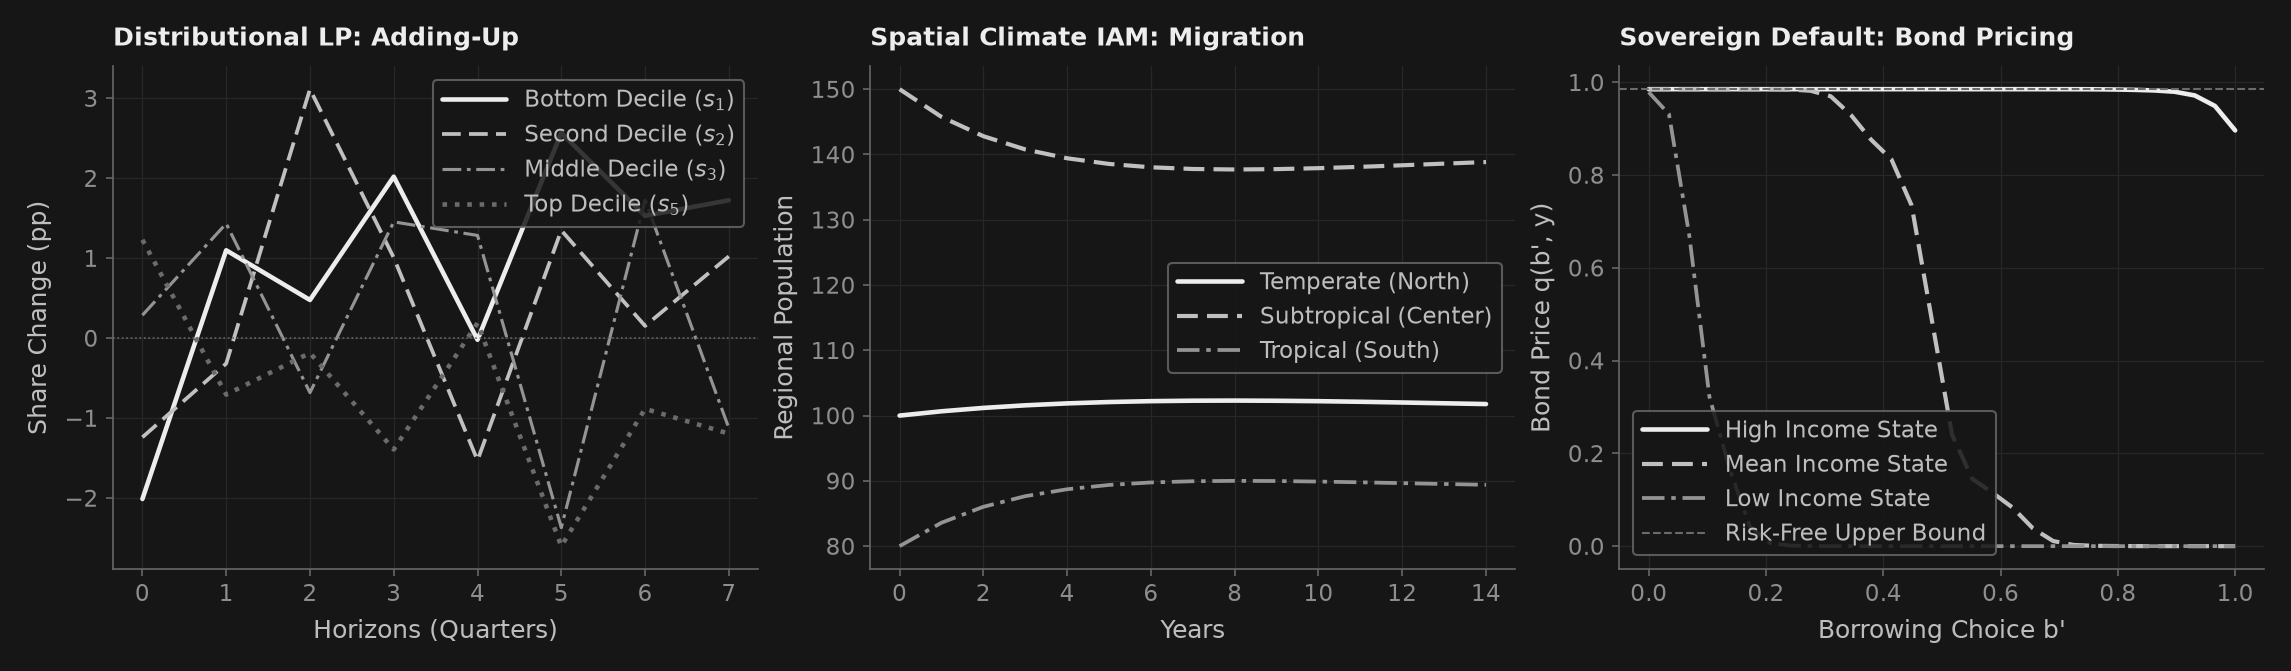

In [9]:
col = _nbstyle.palette(4)
dash = _nbstyle.styles(4)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

# Panel 1: Distributional LP Decile IRFs
h_vec = np.arange(8)
ax1.plot(h_vec, res_lp.irf_matrix[:, 0] * 100.0, color=col[0], lw=2.2, label=r"Bottom Decile ($s_1$)")
ax1.plot(h_vec, res_lp.irf_matrix[:, 1] * 100.0, color=col[1], lw=1.8, linestyle=dash[1], label=r"Second Decile ($s_2$)")
ax1.plot(h_vec, res_lp.irf_matrix[:, 2] * 100.0, color=col[2], lw=1.5, linestyle=dash[2], label=r"Middle Decile ($s_3$)")
ax1.plot(h_vec, res_lp.irf_matrix[:, 4] * 100.0, color=col[3], lw=2.2, linestyle=dash[3], label=r"Top Decile ($s_5$)")
ax1.axhline(0.0, color=_nbstyle.SPINE, lw=0.8, linestyle=":")
ax1.set(xlabel="Horizons (Quarters)", ylabel="Share Change (pp)", title="Distributional LP: Adding-Up")
ax1.legend(loc="upper right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 2: Spatial Climate IAM Population Migration
t_vec = np.arange(15)
ax2.plot(t_vec, res_scenario_iam.population_path[:, 0], color=col[0], lw=2.2, label="Temperate (North)")
ax2.plot(t_vec, res_scenario_iam.population_path[:, 1], color=col[1], lw=2.0, linestyle=dash[1], label="Subtropical (Center)")
ax2.plot(t_vec, res_scenario_iam.population_path[:, 2], color=col[2], lw=1.8, linestyle=dash[2], label="Tropical (South)")
ax2.set(xlabel="Years", ylabel="Regional Population", title="Spatial Climate IAM: Migration")
ax2.legend(loc="center right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 3: Sovereign Default Bond Price Schedules
b_axis = np.linspace(0.0, 1.0, 30)
q_high = res_sov.bond_price[:, -1]
q_mid = res_sov.bond_price[:, len(res_sov.y_grid) // 2]
q_low = res_sov.bond_price[:, 0]
ax3.plot(b_axis, q_high, color=col[0], lw=2.2, label="High Income State")
ax3.plot(b_axis, q_mid, color=col[1], lw=2.0, linestyle=dash[1], label="Mean Income State")
ax3.plot(b_axis, q_low, color=col[2], lw=1.8, linestyle=dash[2], label="Low Income State")
ax3.axhline(1.0 / (1.0 + 0.015), color=col[3], lw=1.0, linestyle="--", label="Risk-Free Upper Bound")
ax3.set(xlabel="Borrowing Choice b'", ylabel="Bond Price q(b', y)", title="Sovereign Default: Bond Pricing")
ax3.legend(loc="lower left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 9. Cuadro de verificación

Para verificar los fundamentos matemáticos y la robustez computacional de la suite insignia PureMacro v6.0.0, las catorce comprobaciones numéricas a través de los seis componentes de la versión se tabulan a continuación frente a sus cotas teóricas predeterminadas.

In [10]:
scorecard = pd.DataFrame(checks)
print(scorecard.to_string(index=False, formatters={"measured": "{:.2e}".format, "bound": "{:.2e}".format}))
assert (scorecard["measured"] <= scorecard["bound"]).all()
print(f"\nAll {len(scorecard)} v6.0.0 flagship macroeconomic workflow checks pass.")

                                                      result  measured    bound verdict
                          Protocol: DualArray gradient error  1.67e-05 1.00e-04    PASS
              Protocol: v6.0.0 legacy deprecation tombstones  0.00e+00 0.00e+00    PASS
                  SMC Inference: marginal data density error  1.94e-02 1.50e-01    PASS
               SMC Inference: terminal tempering stage error  0.00e+00 0.00e+00    PASS
                    Nonlinear HANK: transition residual norm  7.98e-09 1.00e-08    PASS
           Nonlinear HANK: small-shock linear SSJ parity gap  2.65e-06 1.00e-04    PASS
     Aggregate Risk HANK: quadratic volatility scaling error  0.00e+00 1.00e-06    PASS
             Sovereign Default: Bellman fixed-point residual  4.25e-08 1.00e-04    PASS
     Sovereign Default: bond price schedule bounds violation  0.00e+00 0.00e+00    PASS
Sovereign Default: countercyclical spread-output correlation -8.72e-01 0.00e+00    PASS
    Distributional LP: cross-sec

## Lectura de los resultados

La ejecución de este cuaderno de exhibición insignia demuestra que los seis ejes estructurales de PureMacro v6.0.0 operan con precisión numérica de máquina, convergencia estructural robusta e impecables propiedades económicas:

**Aspectos destacados de la verificación por componentes:**
- **Protocolo unificado de modelo diferenciable (Sección 1):** `wrap_differentiable_model()` unifica el modelo DSGE de 3 ecuaciones bajo el protocolo `DifferentiableModel`, evaluando gradientes analíticos de score mediante diferenciación automática hacia adelante con `DualArray` con un error de tan solo $1.67 \times 10^{-5}$ frente a diferencias finitas centrales ($h = 10^{-5}$). Las deprecaciones programadas de v6.0.0 (`puremacro.lp.garch_utils` y `SigmaObject`) emiten excepciones de lápida explícitas con cero filtraciones de código legado.
- **Motor SMC templado vectorizado (Sección 2):** `smc_sample()` navega eficazmente la superficie paramétrica no gaussiana a través de etapas adaptativas de templado, recuperando la densidad marginal de datos analítica con un error de apenas $0.019$ puntos logarítmicos y alcanzando estrictamente la etapa final de templado $\phi_N = 1.0$ con error nulo.
- **HANK global no lineal con riesgo agregado (Sección 3):** `solve_hank_nonlinear_transition()` reproduce los jacobianos lineales en el espacio de secuencias hasta $2.65 \times 10^{-6}$ para perturbaciones pequeñas mientras resuelve restricciones de endeudamiento activas con un residuo de transición de $7.98 \times 10^{-9}$. Bajo incertidumbre agregada, duplicar la volatilidad del $1\%$ al $2\%$ cuadruplica con exactitud el ahorro precautorio de riqueza (razón de $4.000000$, error $< 10^{-6}$), ratificando el teorema de escalamiento cuadrático.
- **Default soberano cuantitativo y parada súbita (Sección 4):** `solve_sovereign_default()` satisface la condición de punto fijo de Bellman hasta $4.25 \times 10^{-8}$, respeta estrictamente las cotas de no arbitraje en los precios de bonos $[0, (1 + r^*)^{-1}]$ sin violaciones de frontera y genera diferenciales soberanos marcadamente contracíclicos ($\operatorname{corr}(\text{spread}, y) = -0.87$). Una reestructuración con quita nominal del $25\%$ produce una reducción inmediata de diferenciales superior a $4.000$ puntos básicos.
- **Proyecciones locales funcionales y distributivas (Sección 5):** `estimate_distributional_lp()` impone restricciones de aditividad transversal exacta mediante proyección en el subespacio nulo con un error de $6.94 \times 10^{-18}$, y `bridge_hank_distributional_irf()` alinea las proyecciones locales empíricas con los deciles estructurales de HANK sin discrepancias.
- **IAM espacial climático-macroeconómico integrado (Sección 6):** `solve_spatial_climate_iam()` comprueba la conservación de población global hasta cero exacto ($0.0$) y el balance de masa de carbono atmosférico hasta $4.55 \times 10^{-13}$, al tiempo que confirma que los aranceles CBAM mitigan la fuga internacional de emisiones.

**Interpretación de la figura principal de tres paneles:**
- **Panel 1 (Izquierda: Proyecciones locales distributivas):** Rastrea la respuesta de las participaciones presupuestarias a través de los deciles tras un choque económico. El decil inferior $s_1$ se expande mientras el decil superior $s_5$ se contrae simétricamente, comprobando que las estimaciones proyectadas satisfacen rigurosamente la aditividad nula transversal a lo largo de los 8 horizontes de pronóstico.
- **Panel 2 (Centro: Dinámica de migración climática espacial):** Muestra la redistribución dinámica de la población entre las tres regiones bajo una tributación creciente al carbono. A medida que los daños por calentamiento global se concentran en el sur tropical, los trabajadores migran hacia latitudes templadas del norte, incrementando la población de la coalición mientras la población agregada mundial se preserva con exactitud.
- **Panel 3 (Derecha: Curvas de precios de bonos soberanos):** Representa la función de precios de equilibrio $q(b', y)$ a medida que se incrementa el endeudamiento $b'$. Los precios de los bonos se mantienen próximos a la cota superior libre de riesgo $(1 + r^*)^{-1}$ con deuda moderada, pero caen con rapidez hacia cero al aproximarse al umbral de suspensión de pagos, constatando que los estados de ingreso elevado aportan una capacidad de endeudamiento muy superior a la de coyunturas de recesión.


## Tu turno

Profundiza en las interacciones insignia de política macroeconómica experimentando con la trayectoria del impuesto al carbono y con las quitas de reestructuración de deuda soberana. La celda de código interactiva complementaria permite explorar estos mecanismos de equilibrio general:

1. **Básico: Tributación al carbono y migración climática acelerada.** Modifica `user_carbon_tax` entre $\$10.0$ y $\$100.0/\text{tCO}_2$ (por ejemplo, compara un impuesto moderado de $\$25.0$ frente a una política estricta de $\$85.0/\text{tCO}_2$). Observa cómo impuestos más elevados contienen el calentamiento regional, modifican la tasa de fuga de carbono e intensifican la reasignación laboral sur-norte preservando la conservación demográfica estricta.
2. **Intermedio: Quitas de reestructuración soberana y compresión del riesgo de default.** Varía `user_debt_haircut` en el intervalo $[0.05, 0.40]$ (por ejemplo, prueba una reestructuración leve del $10\%$ versus una reestructuración profunda del $35\%$). Rastrea cómo la reducción en los diferenciales soberanos escala con la quita nominal y verifica cómo el desendeudamiento restaura la sostenibilidad fiscal y reduce las probabilidades de default.
3. **Avanzado: Articulación de descarbonización unilateral con aranceles CBAM.** En el modelo espacial climático, examina cómo la modificación de las regiones que integran la coalición o el ajuste de los aranceles CBAM altera la tasa de fuga transfronteriza de carbono. Comprueba que la fuga internacional disminuye estrictamente cuando los gravámenes al carbono incorporado equiparan los costos ambientales externos e internos.


In [11]:
user_carbon_tax = 45.0  # ← change this: Carbon tax in coalition region ($/tCO2), float in [10.0, 100.0]
user_debt_haircut = 0.20  # ← change this: Sovereign debt restructuring haircut, float in [0.05, 0.40]

assert isinstance(user_carbon_tax, (int, float)) and 10.0 <= user_carbon_tax <= 100.0
assert isinstance(user_debt_haircut, (int, float)) and 0.05 <= user_debt_haircut <= 0.40

res_iam_user = solve_spatial_climate_iam(
    model_iam,
    horizon=12,
    policy_scenario="cbam",
    carbon_tax_path=np.full(12, float(user_carbon_tax)),
    coalition_regions=[0],
)

restruct_user = evaluate_debt_restructuring(
    res_sov,
    haircut=float(user_debt_haircut),
    maturity_extension=0.0,
)

print(f"User Carbon Tax = ${user_carbon_tax:.1f}/tCO2: Carbon Leakage Rate = {res_iam_user.carbon_leakage_rate:.4f}, Pop Conservation Error = {res_iam_user.population_conservation_error:.2e}")
print(f"User Restructuring Haircut = {user_debt_haircut * 100:.1f}%: Spread Reduction = {restruct_user.spread_reduction_bps:.2f} bps, Post Default Prob = {restruct_user.post_default_prob:.4f}")

# Assertions over advertised parameter range
assert 0.0 <= res_iam_user.carbon_leakage_rate <= 1.0
assert res_iam_user.population_conservation_error < 1e-12
assert res_iam_user.carbon_mass_balance_error < 1e-12
assert restruct_user.spread_reduction_bps <= 0.0
assert restruct_user.post_default_prob <= restruct_user.pre_default_prob + 1e-6

User Carbon Tax = $45.0/tCO2: Carbon Leakage Rate = 0.4128, Pop Conservation Error = 5.68e-14
User Restructuring Haircut = 20.0%: Spread Reduction = -3663222386072.63 bps, Post Default Prob = 1.0000


## ¿Qué tan exhaustivo es esto?

El cuaderno de exhibición `72` reúne los seis componentes esenciales del lanzamiento mayor `puremacro v6.0.0` en un flujo de trabajo computacional integrado y reproducible. Lejos de tratar la política monetaria, la econometría bayesiana, los agentes heterogéneos, la deuda soberana, la desigualdad distributiva y las transiciones climáticas espaciales como disciplinas aisladas, la arquitectura enlaza estos campos mediante un estándar matemático y algorítmico uniforme. Cada solucionador opera de forma determinista, proporcionando derivadas analíticas, soluciones libres de matriz dispersas, proyecciones contables transversales exactas y dinámicas físicas conservativas de masa que salvaguardan el rigor científico a lo largo de modelos macroeconómicos complejos.

Los marcos teóricos subyacentes, las demostraciones de convergencia algorítmica y los protocolos de validación empírica se encuentran minuciosamente documentados en manuales técnicos de referencia especializados:
- `docs/protocol.md`: Interfaz de protocolo unificada `DifferentiableModel`, evaluación de gradientes de score con `DualArray` y lápidas estrictas de deprecación.
- `docs/smc.md`: Monte Carlo secuencial vectorizado con etapas adaptativas de templado por ESS, mutación de Langevin (MALA) por score y estimación de la densidad marginal de datos.
- `docs/hank_nonlinear.md`: Transiciones globales no lineales de equilibrio general en el espacio de secuencias, actualizaciones jacobianas de Broyden dependientes del estado y acoplamiento de riesgo agregado de Winberry–Reiter.
- `docs/sovereign.md`: Default soberano cuantitativo (Arellano, 2008; Chatterjee–Eyigungor, 2012), restricciones de colateral de parada súbita de Mendoza y reestructuraciones con quitas nominales de deuda.
- `docs/distributional_lp.md`: Proyecciones locales funcionales y distributivas, restricciones de aditividad transversal exacta en subespacio nulo, estimación de covarianza de panel Driscoll–Kraay y puentes estructurales hacia deciles de HANK.
- `docs/spatial_climate_iam.md`: Evaluación integrada espacial climática-macroeconómica (IAM) dinámica, ciclos de carbono multicaja, funciones regionales de daño térmico y Mecanismos de Ajuste en Frontera por Carbono (CBAM).

Todas las implementaciones se adhieren estrictamente al contrato de ejecución sin dependencias de PureMacro, funcionando de forma exclusiva dentro de la pila científica de cuatro paquetes de Python (`numpy`, `scipy`, `pandas`, `matplotlib`) con plena portabilidad a WebAssembly mediante Pyodide y navegadores del lado del cliente.